In [1]:
# The ML backend of Label Studio, step by step
# Computer Vision & Heritage, session 2 (annotation with Label Studio, ML backend and active learning), part 2
# Goal: rebuild, without a server, the ML backend (model.py): predict(), then train(), started by fit() (retraining).
import json
import os
import shutil
import time
from urllib.parse import unquote

import matplotlib.pyplot as plt
import numpy as np
import yaml
from ultralytics import YOLO

In [2]:
ASSETS = os.path.join("..", "datasets", "dataset-s02-2")

In [3]:
# Document root of Label Studio (LABEL_STUDIO_LOCAL_FILES_DOCUMENT_ROOT): the parent of the image folder,
# which is the Local Files storage of the project
DOCUMENT_ROOT = os.path.dirname(ASSETS)

In [4]:
DOCUMENT_ROOT

'../datasets'

In [5]:
# Folder of the backend (MODEL_DIR): the datasets, the training runs and the trained models (data/: not versioned)
MODEL_DIR = os.path.abspath(os.path.join(ASSETS, "..", "data"))

In [6]:
MODEL_DIR

'.../datasets/data'

In [7]:
# Generic model: any Ultralytics detection model (file or name)
MODEL = "yolo26n.pt"

In [8]:
# __init__(): no training yet for the project, so the generic model
# (first run: downloads the weights yolo26n.pt, 5.5 MB, into this folder)
model = YOLO(MODEL)

In [9]:
# --- 1. The tasks, as Label Studio sends them to predict() ---
# A test task, written by hand with the keys predict() reads (Label Studio sends the whole task)
# Local files storage: after "?d=", the path of the image relative to DOCUMENT_ROOT
task = {"id": 1, "data": {"image": "/data/local-files/?d=dataset-s02-2/predict-marginal-bird.jpg"}}

In [10]:
task

{'id': 1,
 'data': {'image': '/data/local-files/?d=dataset-s02-2/predict-marginal-bird.jpg'}}

In [11]:
# predict() receives a list of tasks: here, one
tasks = [task]

In [12]:
tasks

[{'id': 1,
  'data': {'image': '/data/local-files/?d=dataset-s02-2/predict-marginal-bird.jpg'}}]

In [13]:
# The URL of the image: key "image" of the task data ($image in the labeling configuration)
url = task["data"]["image"]

In [14]:
url

'/data/local-files/?d=dataset-s02-2/predict-marginal-bird.jpg'

In [15]:
# Split once at "?d=": the route of Label Studio's local files, then the path relative to DOCUMENT_ROOT
url.split("?d=", 1)

['/data/local-files/', 'dataset-s02-2/predict-marginal-bird.jpg']

In [16]:
# The last part; unquote decodes the characters Label Studio escapes in the URL (%20 -> space)
unquote(url.split("?d=", 1)[-1])

'dataset-s02-2/predict-marginal-bird.jpg'

In [17]:
# Path of the image on disk (model.py)
def image_path(url):
    # Local files storage: /data/local-files/?d=<path relative to DOCUMENT_ROOT>
    # (images imported with Data Import, /data/upload/...: not found, use a Local Files storage)
    return os.path.join(DOCUMENT_ROOT, unquote(url.split("?d=", 1)[-1]))

In [18]:
# model.py, predict(): the path of the image of each task
img_path_list = []

In [19]:
for task in tasks:
    img_path = image_path(task['data']['image'])
    print(img_path)
    img_path_list.append(img_path)

../datasets/dataset-s02-2/predict-marginal-bird.jpg


In [20]:
img_path_list

['../datasets/dataset-s02-2/predict-marginal-bird.jpg']

In [21]:
# The backend opens the file itself: it must see DOCUMENT_ROOT too
os.path.exists(img_path_list[0])

True

In [22]:
# --- 2. Prediction: one call for the images of all the tasks ---
results = model.predict(img_path_list)

0: 640x416 1 bird, 1 book, 47.8ms


Speed: 1.3ms preprocess, 47.8ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 416)


In [23]:
# A list: one Results object per image
results

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 colors: None
 depth: None
 keypoints: None
 masks: None
 names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair',

In [24]:
result = results[0]

In [25]:
type(result)

ultralytics.engine.results.Results

In [26]:
# (H, W): rows first
result.orig_shape

(1566, 1000)

In [27]:
# Class index -> class name (the dictionary is printed above, in results): the 80 classes of COCO,
# the only labels this model gives
len(result.names)

80

In [28]:
result.boxes

ultralytics.engine.results.Boxes object with attributes:

cls: tensor([14., 73.])
conf: tensor([0.4197, 0.4099])
data: tensor([[6.2953e+01, 7.6014e+02, 1.4726e+02, 9.7889e+02, 4.1966e-01, 1.4000e+01],
        [4.9831e+01, 2.5121e+01, 1.0000e+03, 1.5285e+03, 4.0992e-01, 7.3000e+01]])
id: None
is_track: False
orig_shape: (1566, 1000)
shape: torch.Size([2, 6])
xywh: tensor([[ 105.1054,  869.5138,   84.3046,  218.7574],
        [ 524.9153,  776.7948,  950.1693, 1503.3472]])
xywhn: tensor([[0.1051, 0.5552, 0.0843, 0.1397],
        [0.5249, 0.4960, 0.9502, 0.9600]])
xyxy: tensor([[  62.9531,  760.1351,  147.2578,  978.8925],
        [  49.8307,   25.1212, 1000.0000, 1528.4684]])
xyxyn: tensor([[0.0630, 0.4854, 0.1473, 0.6251],
        [0.0498, 0.0160, 1.0000, 0.9760]])

In [29]:
# Corners (x1, y1, x2, y2) in pixels: one row per box
result.boxes.xyxy

tensor([[  62.9531,  760.1351,  147.2578,  978.8925],
        [  49.8307,   25.1212, 1000.0000, 1528.4684]])

In [30]:
# Class index of each box
result.boxes.cls

tensor([14., 73.])

In [31]:
# Confidence score of each box
result.boxes.conf

tensor([0.4197, 0.4099])

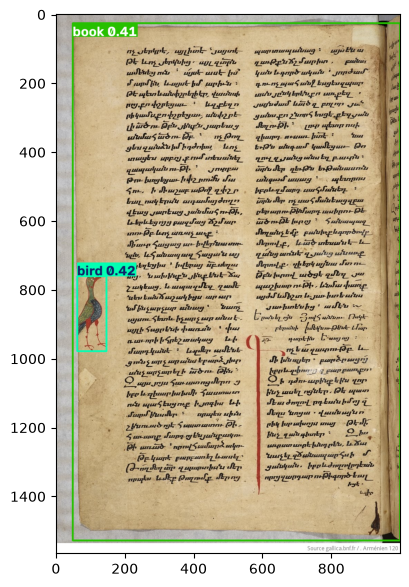

In [32]:
# The boxes of the model: bird, in the margin; book, almost the whole page
# plot() returns BGR: [:, :, ::-1] -> RGB for matplotlib
plt.figure(figsize=(4.5, 7))
plt.imshow(result.plot()[:, :, ::-1])
plt.show()

In [33]:
# --- 3. One box: from pixels to percent of the image size ---
# Width and height of the image, in pixels (orig_shape: (H, W))
orig_w, orig_h = result.orig_shape[1], result.orig_shape[0]

In [34]:
orig_w

1000

In [35]:
orig_h

1566

In [36]:
# The first box: a row of xyxy, of cls and of conf (the loop of predict() goes through the rows)
box = result.boxes.xyxy[0]

In [37]:
box

tensor([ 62.9531, 760.1351, 147.2578, 978.8925])

In [38]:
class_id = result.boxes.cls[0]

In [39]:
class_id

tensor(14.)

In [40]:
score = result.boxes.conf[0]

In [41]:
score

tensor(0.4197)

In [42]:
# Its corners, as Python numbers
box.tolist()

[62.95314025878906, 760.1350708007812, 147.25775146484375, 978.8924560546875]

In [43]:
x1, y1, x2, y2 = box.tolist()

$$x = 100\,\frac{x_1}{W} \qquad y = 100\,\frac{y_1}{H} \qquad \text{width} = 100\,\frac{x_2 - x_1}{W} \qquad \text{height} = 100\,\frac{y_2 - y_1}{H}$$

In [44]:
# Label Studio: top-left corner (x, y) and size, in percent of the width W and the height H (YOLO: centre, in [0, 1])
normalized_x1, normalized_y1 = (x1 / orig_w) * 100, (y1 / orig_h) * 100

In [45]:
normalized_x1

6.295314025878906

In [46]:
normalized_y1

48.539915121378115

In [47]:
# The bottom-right corner, in percent
normalized_x2, normalized_y2 = (x2 / orig_w) * 100, (y2 / orig_h) * 100

In [48]:
normalized_x2

14.725775146484374

In [49]:
normalized_y2

62.50909681064416

In [50]:
width = normalized_x2 - normalized_x1

In [51]:
width

8.430461120605468

In [52]:
height = normalized_y2 - normalized_y1

In [53]:
height

13.969181689266044

In [54]:
# --- 4. The same box as a Label Studio region ---
# The class index is a float tensor: .item() gives the Python number, int() the index
int(class_id.item())

14

In [55]:
# Its class name: the label of the region
class_name = result.names[int(class_id.item())]

In [56]:
class_name

'bird'

In [57]:
# Its score, as a Python number
float(score.item())

0.4196571409702301

In [58]:
# A region: the tags it fills (labeling configuration: <RectangleLabels name="label" toName="image">,
# <Image name="image">), the size of the image, the box in percent and its label, its score
record = {
    "from_name": "label",
    "to_name": "image",
    "type": "rectanglelabels",
    "original_width": orig_w,
    "original_height": orig_h,
    "image_rotation": 0,
    "value": {
        "x": normalized_x1,
        "y": normalized_y1,
        "width": width,
        "height": height,
        "rotation": 0,
        "rectanglelabels": [class_name]
    },
    "score": float(score.item()),
}

In [59]:
record

{'from_name': 'label',
 'to_name': 'image',
 'type': 'rectanglelabels',
 'original_width': 1000,
 'original_height': 1566,
 'image_rotation': 0,
 'value': {'x': 6.295314025878906,
  'y': 48.539915121378115,
  'width': 8.430461120605468,
  'height': 13.969181689266044,
  'rotation': 0,
  'rectanglelabels': ['bird']},
 'score': 0.4196571409702301}

In [60]:
# --- 5. All the boxes of the image: the prediction of the task (model.py, predict()) ---
records = []

In [61]:
# One region per box (an empty Boxes object counts as false: no box, no region)
if result.boxes:
    orig_w, orig_h = result.orig_shape[1], result.orig_shape[0]

    for box, class_id, score in zip(result.boxes.xyxy,
                                    result.boxes.cls,
                                    result.boxes.conf):

        x1, y1, x2, y2 = box.tolist()
        normalized_x1, normalized_y1 = (x1 / orig_w) * 100, (y1 / orig_h) * 100
        normalized_x2, normalized_y2 = (x2 / orig_w) * 100, (y2 / orig_h) * 100

        width = normalized_x2 - normalized_x1
        height = normalized_y2 - normalized_y1

        class_name = result.names[int(class_id.item())]

        records.append(
            {
                "from_name": "label",
                "to_name": "image",
                "type": "rectanglelabels",
                "original_width": orig_w,
                "original_height": orig_h,
                "image_rotation": 0,
                "value": {
                    "x": normalized_x1,
                    "y": normalized_y1,
                    "width": width,
                    "height": height,
                    "rotation": 0,
                    "rectanglelabels": [class_name]
                },
                "score": float(score.item()),
            }
        )

In [62]:
# Bird and book, two classes of the model; predict() keeps only the labels of the project (section 6), here the
# 80 classes of the model
records

[{'from_name': 'label',
  'to_name': 'image',
  'type': 'rectanglelabels',
  'original_width': 1000,
  'original_height': 1566,
  'image_rotation': 0,
  'value': {'x': 6.295314025878906,
   'y': 48.539915121378115,
   'width': 8.430461120605468,
   'height': 13.969181689266044,
   'rotation': 0,
   'rectanglelabels': ['bird']},
  'score': 0.4196571409702301},
 {'from_name': 'label',
  'to_name': 'image',
  'type': 'rectanglelabels',
  'original_width': 1000,
  'original_height': 1566,
  'image_rotation': 0,
  'value': {'x': 4.983072662353515,
   'y': 1.6041660674230347,
   'width': 95.01692733764648,
   'height': 95.99917900212118,
   'rotation': 0,
   'rectanglelabels': ['book']},
  'score': 0.4099188446998596}]

In [63]:
# The first one is the region built in section 4
records[0] == record

True

In [64]:
# Score of each region
[r["score"] for r in records]

[0.4196571409702301, 0.4099188446998596]

In [65]:
# Score of the task: their mean (Data Manager: "Order by Prediction score", lowest first = least certain first)
float(np.mean([r["score"] for r in records]))

0.41478799283504486

In [66]:
# One prediction per task
predictions = []

In [67]:
predictions.append(
    {
        "result": records,
        # Score of the task: mean confidence of its boxes (0 without a box);
        # Data Manager: "Order by Prediction score", lowest first = least certain first
        "score": float(np.mean([r["score"] for r in records])) if records else 0.0,
    }
)

In [68]:
# As JSON, what Label Studio receives: the server of the backend sends the predictions under "results"
print(json.dumps({"results": predictions}, indent=1))

{
 "results": [
  {
   "result": [
    {
     "from_name": "label",
     "to_name": "image",
     "type": "rectanglelabels",
     "original_width": 1000,
     "original_height": 1566,
     "image_rotation": 0,
     "value": {
      "x": 6.295314025878906,
      "y": 48.539915121378115,
      "width": 8.430461120605468,
      "height": 13.969181689266044,
      "rotation": 0,
      "rectanglelabels": [
       "bird"
      ]
     },
     "score": 0.4196571409702301
    },
    {
     "from_name": "label",
     "to_name": "image",
     "type": "rectanglelabels",
     "original_width": 1000,
     "original_height": 1566,
     "image_rotation": 0,
     "value": {
      "x": 4.983072662353515,
      "y": 1.6041660674230347,
      "width": 95.01692733764648,
      "height": 95.99917900212118,
      "rotation": 0,
      "rectanglelabels": [
       "book"
      ]
     },
     "score": 0.4099188446998596
    }
   ],
   "score": 0.41478799283504486
  }
 ]
}


In [69]:
# --- 6. predict() of the backend, without the server: the bodies of the methods in model.py (model: self.model) ---
# Mode detect: the regions of a result come from boxes() (model.py: self.to_regions)
def boxes(result):
    records = []
    if result.boxes:
        orig_w, orig_h = result.orig_shape[1], result.orig_shape[0]

        for box, class_id, score in zip(result.boxes.xyxy,
                                        result.boxes.cls,
                                        result.boxes.conf):

            x1, y1, x2, y2 = box.tolist()
            normalized_x1, normalized_y1 = (x1 / orig_w) * 100, (y1 / orig_h) * 100
            normalized_x2, normalized_y2 = (x2 / orig_w) * 100, (y2 / orig_h) * 100

            width = normalized_x2 - normalized_x1
            height = normalized_y2 - normalized_y1

            class_name = result.names[int(class_id.item())]

            records.append(
                {
                    "from_name": "label",
                    "to_name": "image",
                    "type": "rectanglelabels",
                    "original_width": orig_w,
                    "original_height": orig_h,
                    "image_rotation": 0,
                    "value": {
                        "x": normalized_x1,
                        "y": normalized_y1,
                        "width": width,
                        "height": height,
                        "rotation": 0,
                        "rectanglelabels": [class_name]
                    },
                    "score": float(score.item()),
                }
            )
    return records

In [70]:
# Labels of the project, in the order of the YOLO classes: here the 80 classes of the model
# (a project created by labelstudio_yolo.py; model.py reads them in the labeling configuration)
names = list(model.names.values())

In [71]:
# model.py, known(): a predicted region whose label is a label of the project (caption: any text)
def known(record):
    if record["type"] == "textarea":
        return True
    return record["value"][record["type"]][0] in names

In [72]:
def predict(tasks):
    img_path_list = []
    for task in tasks:
        img_path = image_path(task['data']['image'])
        print(img_path)
        img_path_list.append(img_path)

    results = model.predict(img_path_list)

    predictions = []
    for result in results:
        # The regions of the mode, with a label of the project only (the model can know other classes)
        records = [r for r in boxes(result) if known(r)]
        scores = [r["score"] for r in records if "score" in r]
        predictions.append(
            {
                "result": records,
                # Score of the task: mean confidence of its regions (0 without a region);
                # Data Manager: "Order by Prediction score", lowest first = least certain first
                "score": float(np.mean(scores)) if scores else 0.0,
            }
        )
    return predictions

In [73]:
# What predict() returns (the server sends it under "results"): the predictions of section 5
predict(tasks) == predictions

../datasets/dataset-s02-2/predict-marginal-bird.jpg



0: 640x416 1 bird, 1 book, 43.3ms


Speed: 1.0ms preprocess, 43.3ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 416)


True

In [74]:
# --- 7. fit(), then train(), step 1: the annotated tasks, as Label Studio exports them ---
# Start Training (Settings > Model) sends START_TRAINING to fit(), which runs train() in a thread;
# train() first exports the annotated tasks of the project (JSON export, through the Label Studio API)
# The annotator corrects the prediction: deletes the book box (the whole page), keeps the bird, then submits
# (was_cancelled: True for a skipped task)
annotation = {"result": [r for r in records if r["value"]["rectanglelabels"] != ["book"]], "was_cancelled": False}

In [75]:
annotation

{'result': [{'from_name': 'label',
   'to_name': 'image',
   'type': 'rectanglelabels',
   'original_width': 1000,
   'original_height': 1566,
   'image_rotation': 0,
   'value': {'x': 6.295314025878906,
    'y': 48.539915121378115,
    'width': 8.430461120605468,
    'height': 13.969181689266044,
    'rotation': 0,
    'rectanglelabels': ['bird']},
   'score': 0.4196571409702301}],
 'was_cancelled': False}

In [76]:
# The JSON export of the project: a list of tasks, here one, with the keys train() reads
# (the export has more: predictions, created_at...)
tasks = [{"id": task["id"], "data": task["data"], "annotations": [annotation]}]

In [77]:
tasks

[{'id': 1,
  'data': {'image': '/data/local-files/?d=dataset-s02-2/predict-marginal-bird.jpg'},
  'annotations': [{'result': [{'from_name': 'label',
      'to_name': 'image',
      'type': 'rectanglelabels',
      'original_width': 1000,
      'original_height': 1566,
      'image_rotation': 0,
      'value': {'x': 6.295314025878906,
       'y': 48.539915121378115,
       'width': 8.430461120605468,
       'height': 13.969181689266044,
       'rotation': 0,
       'rectanglelabels': ['bird']},
      'score': 0.4196571409702301}],
    'was_cancelled': False}]}]

In [78]:
# --- 8. train(), step 2: one region, from Label Studio to a line of a YOLO label file ---
# The labels of the project (section 6), in the order of the YOLO classes
len(names)

80

In [79]:
# The annotations of the first task, without the cancelled ones
annotations = [a for a in tasks[0]["annotations"] if not a["was_cancelled"]]

In [80]:
len(annotations)

1

In [81]:
# The last annotation (a task can be annotated more than once), its first region
region = annotations[-1]["result"][0]

In [82]:
# train() keeps the boxes (rectanglelabels) whose label is a label of the project
region["type"]

'rectanglelabels'

In [83]:
# Label Studio: top-left corner and size, in percent of the image size
v = region["value"]

In [84]:
v

{'x': 6.295314025878906,
 'y': 48.539915121378115,
 'width': 8.430461120605468,
 'height': 13.969181689266044,
 'rotation': 0,
 'rectanglelabels': ['bird']}

$$x_c = \frac{x + \text{width}/2}{100} \qquad y_c = \frac{y + \text{height}/2}{100} \qquad w = \frac{\text{width}}{100} \qquad h = \frac{\text{height}}{100}$$

In [85]:
# YOLO: centre and size, in [0, 1] of the image size
x_center = (v["x"] + v["width"] / 2) / 100

In [86]:
x_center

0.10510544586181642

In [87]:
y_center = (v["y"] + v["height"] / 2) / 100

In [88]:
y_center

0.5552450596601113

In [89]:
# Class index: the position of the label in names (here, the class index of the model)
names.index(v["rectanglelabels"][0])

14

In [90]:
# The line of the label file: class index, centre, size
f"{names.index(v['rectanglelabels'][0])} {x_center} {y_center} {v['width'] / 100} {v['height'] / 100}"

'14 0.10510544586181642 0.5552450596601113 0.08430461120605467 0.13969181689266044'

In [91]:
# The same box, normalised by Ultralytics (xywhn: centre and size in [0, 1]): the conversion gives it back
result.boxes.xywhn[0]

tensor([0.1051, 0.5552, 0.0843, 0.1397])

In [92]:
# --- 9. train(), step 2: the YOLO dataset of the project, in train/ and val/: images/, labels/, data.yaml ---
# Id of the project in Label Studio (model.py: self.project_id; here, a test project)
project_id = 1

In [93]:
dataset = os.path.join(MODEL_DIR, "datasets", f"project-{project_id}")

In [94]:
dataset

'.../datasets/data/datasets/project-1'

In [95]:
# Built again at each training: the annotations change
shutil.rmtree(dataset, ignore_errors=True)

In [96]:
# The annotated tasks, each with the regions of its last annotation (the cancelled ones left out)
annotated = []

In [97]:
for task in tasks:
    annotations = [a for a in task["annotations"] if not a["was_cancelled"]]
    if annotations:
        annotated.append((task, annotations[-1]["result"]))

In [98]:
len(annotated)

1

In [99]:
# Validation: the tasks whose id is a multiple of 5 (none, or all: validation on the training images)
val_ids = {task["id"] for task, _ in annotated if task["id"] % 5 == 0}

In [100]:
# Task 1: its id is not a multiple of 5, no validation task (validation on the training image)
val_ids

set()

In [101]:
# model.py, yolo_boxes() (mode detect): the line of section 8, for each box of an annotation
def yolo_boxes(regions, names):
    lines = []
    for region in regions:
        v = region["value"]
        # Boxes only, with a label of the project
        if region["type"] != "rectanglelabels" or v["rectanglelabels"][0] not in names:
            continue
        # Label Studio: top-left corner and size, in percent; YOLO: center and size, in [0, 1]
        x_center = (v["x"] + v["width"] / 2) / 100
        y_center = (v["y"] + v["height"] / 2) / 100
        lines.append(f"{names.index(v['rectanglelabels'][0])} {x_center} {y_center} "
                     f"{v['width'] / 100} {v['height'] / 100}")
    return lines

In [102]:
counts = {"train": 0, "val": 0}

In [103]:
n_regions = 0

In [104]:
# model.py, train(), step 2 (mode detect): for each annotated task, its image in images/<split>/ and its label file
# in labels/<split>/
for task, regions in annotated:
    split = "val" if task["id"] in val_ids else "train"
    img_path = image_path(task["data"]["image"])
    name = f"task-{task['id']}"
    folder = os.path.join(dataset, "images", split)
    os.makedirs(folder, exist_ok=True)
    shutil.copy(img_path, os.path.join(folder, name + os.path.splitext(img_path)[1]))
    counts[split] += 1
    lines = yolo_boxes(regions, names)
    os.makedirs(os.path.join(dataset, "labels", split), exist_ok=True)
    with open(os.path.join(dataset, "labels", split, name + ".txt"), "w") as f:
        f.write("".join(line + "\n" for line in lines))
    n_regions += len(lines)

In [105]:
os.listdir(os.path.join(dataset, "images", "train"))

['task-1.jpg']

In [106]:
os.listdir(os.path.join(dataset, "labels", "train"))

['task-1.txt']

In [107]:
# The label file of the task: one line per box (the line of section 8)
with open(os.path.join(dataset, "labels", "train", name + ".txt")) as f:
    print(f.read())

14 0.10510544586181642 0.5552450596601113 0.08430461120605467 0.13969181689266044



In [108]:
# No validation task: validation on the training images
config = {"path": dataset, "train": "images/train", "val": "images/val" if val_ids else "images/train", "names": names}

In [109]:
data = os.path.join(dataset, "data.yaml")

In [110]:
data

'.../datasets/data/datasets/project-1/data.yaml'

In [111]:
with open(data, "w") as f:
    yaml.safe_dump(config, f)

In [112]:
# data.yaml (safe_dump sorts the keys): the 80 names, the folder of the dataset, its train and val images
with open(data) as f:
    print(f.read())

names:
- person
- bicycle
- car
- motorcycle
- airplane
- bus
- train
- truck
- boat
- traffic light
- fire hydrant
- stop sign
- parking meter
- bench
- bird
- cat
- dog
- horse
- sheep
- cow
- elephant
- bear
- zebra
- giraffe
- backpack
- umbrella
- handbag
- tie
- suitcase
- frisbee
- skis
- snowboard
- sports ball
- kite
- baseball bat
- baseball glove
- skateboard
- surfboard
- tennis racket
- bottle
- wine glass
- cup
- fork
- knife
- spoon
- bowl
- banana
- apple
- sandwich
- orange
- broccoli
- carrot
- hot dog
- pizza
- donut
- cake
- chair
- couch
- potted plant
- bed
- dining table
- toilet
- tv
- laptop
- mouse
- remote
- keyboard
- cell phone
- microwave
- oven
- toaster
- sink
- refrigerator
- book
- clock
- vase
- scissors
- teddy bear
- hair drier
- toothbrush
path: .../datasets/data/datasets/project-1
train: images/train
val: images/train



In [113]:
print("Dataset:", counts["train"], "training images,", counts["val"] or "the same", "for validation,",
      n_regions, "regions,", len(names), "labels")

Dataset: 1 training images, the same for validation, 1 regions, 80 labels


In [114]:
# --- 10. train(), step 3: training, from the generic model of the mode ---
# Name of the training: the project and the date (the version of the new model)
version = f"project-{project_id}-{time.strftime('%Y%m%d-%H%M%S')}"

In [115]:
version

'project-1-20261127-170634'

In [116]:
# Number of epochs (model.py: TRAIN_EPOCHS, 10 by default)
EPOCHS = 10

In [117]:
# A new generic model: the training starts from its weights
model = YOLO(MODEL)

In [118]:
# The log: for each epoch, the losses, then the scores on the validation images (here, the training image itself);
# P, R: precision, recall; mAP50, mAP50-95: mean average precision (named in session 1, defined later)
# WARNING "len() of unsized object": from the plot of the labels (labels.jpg) with a single box; the training goes on
# metrics: the scores returned by train(), not displayed (a long object)
metrics = model.train(data=data, epochs=EPOCHS, workers=0,
                      project=os.path.join(MODEL_DIR, "runs"), name=version)

New https://pypi.org/project/ultralytics/8.4.220 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.216 🚀 Python-3.12.4 torch-2.15.0 CPU (Apple M3)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=.../datasets/data/datasets/project-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=project-1-20261127-170634, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, pers


                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


... (92 outputs left out)

                   all          1          1      0.965          1      0.995      0.995


                  bird          1          1      0.965          1      0.995      0.995


Speed: 0.5ms preprocess, 44.7ms inference, 0.0ms loss, 1.0ms postprocess per image


Results saved to .../datasets/data/runs/project-1-20261127-170634


In [119]:
# Its best model: the weights of the epoch with the highest mAP50-95 on the validation images; on a tie, the latest
# (here 0.995 at every epoch: the 10th)
model.trainer.best

PosixPath('.../datasets/data/runs/project-1-20261127-170634/weights/best.pt')

In [120]:
# train(), step 4: best.pt copied into the models of the backend, the model of the project
# (model.py then stores its path in the cache of the backend: self.set("model_path", model_path))
model_path = os.path.join(MODEL_DIR, "models", version + ".pt")

In [121]:
os.makedirs(os.path.dirname(model_path), exist_ok=True)

In [122]:
shutil.copy(model.trainer.best, model_path)

'.../datasets/data/models/project-1-20261127-170634.pt'

In [123]:
# The last line of train() in the log of the backend
print("New model:", model_path)

New model: .../datasets/data/models/project-1-20261127-170634.pt


In [124]:
# --- 11. The next request: __init__() loads the model of the project (model.py: self.get("model_path")) ---
model = YOLO(model_path)

In [125]:
# Its version (/setup): new, so Label Studio asks for the predictions again
os.path.basename(model_path)

'project-1-20261127-170634.pt'

In [126]:
# The prediction of the retrained model: the bird with a higher score;
# after 10 epochs on one image, the book box is still there
predict(tasks)

../datasets/dataset-s02-2/predict-marginal-bird.jpg



0: 640x416 1 bird, 1 book, 40.1ms


Speed: 0.9ms preprocess, 40.1ms inference, 0.5ms postprocess per image at shape (1, 3, 640, 416)


[{'result': [{'from_name': 'label',
    'to_name': 'image',
    'type': 'rectanglelabels',
    'original_width': 1000,
    'original_height': 1566,
    'image_rotation': 0,
    'value': {'x': 6.4135391235351555,
     'y': 48.45434897704143,
     'width': 8.647091674804688,
     'height': 13.968737372036635,
     'rotation': 0,
     'rectanglelabels': ['bird']},
    'score': 0.7071669101715088},
   {'from_name': 'label',
    'to_name': 'image',
    'type': 'rectanglelabels',
    'original_width': 1000,
    'original_height': 1566,
    'image_rotation': 0,
    'value': {'x': 5.013642501831055,
     'y': 1.5124510987965083,
     'width': 94.77761116027833,
     'height': 95.92242758545078,
     'rotation': 0,
     'rectanglelabels': ['book']},
    'score': 0.4223719537258148}],
  'score': 0.5647694319486618}]

In [127]:
results = model.predict(img_path_list)

0: 640x416 1 bird, 1 book, 37.8ms


Speed: 0.8ms preprocess, 37.8ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 416)


In [128]:
# Scores of the boxes after the training (before: section 2)
results[0].boxes.conf

tensor([0.7072, 0.4224])

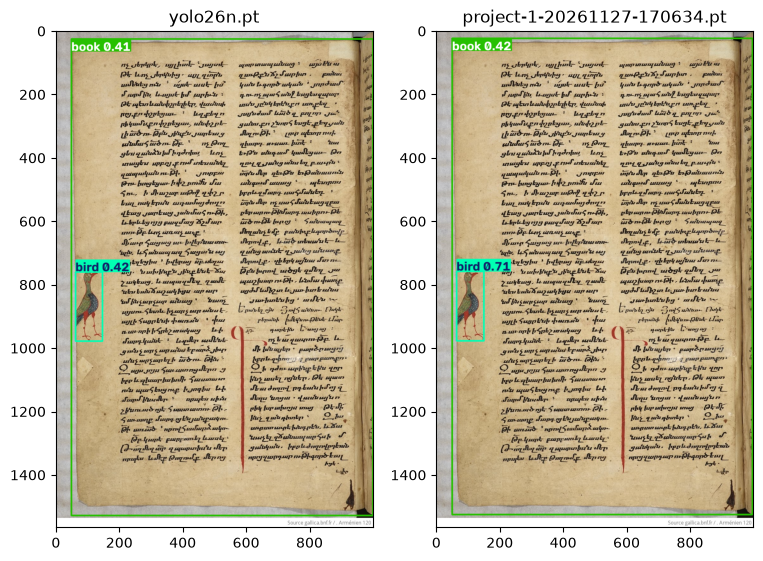

In [129]:
# Before (generic model, section 2) and after the training. Checked on the training image itself:
# the training works; nothing is known yet on new images
fig, axes = plt.subplots(1, 2, figsize=(9, 7))
axes[0].imshow(result.plot()[:, :, ::-1])
axes[0].set_title(MODEL)
axes[1].imshow(results[0].plot()[:, :, ::-1])
axes[1].set_title(os.path.basename(model_path))
plt.show()